# MMA3001 — Faster R-CNN Four-Class Object Detection

## Aim

Evaluate the previously trained Faster R-CNN ResNet50-FPN V2 model for detecting and localising four pork rasher packaging defects.

## Defect Classes

1. loose-meat
2. packaging-error
3. twisted-meat
4. unsealed

## Objectives

- Verify the original four-class dataset and annotation conversion.
- Load the saved best checkpoint without retraining.
- Analyse the recorded 15-epoch training history.
- Calculate overall and per-class COCO-style validation metrics.
- Examine confidence-threshold performance and confusion matrices.
- Compare Micro-F1, Macro-F1 and per-class recall.
- Evaluate model parameters, checkpoint size, inference speed and memory usage.

## Evaluation Protocol

The original dataset, checkpoint and training records are stored on Google Drive. Shared Python functions are imported from the `mma3001` GitHub package.

Confidence thresholds are analysed using validation data only. Test-set evaluation is reserved for the final three-model comparison in Notebook 07.

This notebook does not regenerate datasets or repeat model training.

In [1]:

# Install dependencies for saved-checkpoint evaluation.
%pip install -q torchmetrics pycocotools pandas matplotlib pyyaml pillow


In [2]:

# Configure Google Drive storage and shared Python modules.

import gc
import os
import subprocess
import sys
import time

from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import torch

from IPython.display import display
from google.colab import drive
from torch.utils.data import DataLoader
from torchmetrics.detection.mean_ap import MeanAveragePrecision

# Use the same GitHub repository URL as Notebooks 03–05.
REPO_URL = "https://github.com/daniellawjmcc/MMA3001_Project.git"
REPO_ROOT = Path("/content/MMA3001_Project_repo")

DRIVE_ROOT = Path("/content/gdrive_new")
DEFAULT_PROJECT_ROOT = (
    DRIVE_ROOT / "MyDrive" / "MMA3001_Project"
)

if not DEFAULT_PROJECT_ROOT.is_dir():
    drive.mount(str(DRIVE_ROOT))

if not REPO_ROOT.exists():
    subprocess.run(
        ["git", "clone", REPO_URL, str(REPO_ROOT)],
        check=True,
    )
else:
    subprocess.run(
        ["git", "-C", str(REPO_ROOT), "pull", "--ff-only"],
        check=True,
    )

source_path = str(REPO_ROOT / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)

from mma3001.config import (
    FOUR_CLASS_NAMES,
    SEED,
    find_project_root,
    get_dataset_path,
    get_run_path,
    get_checkpoint_path,
    set_seed,
)

from mma3001.dataset import (
    YoloDetectionDataset,
    detection_collate_fn,
    load_class_names,
    read_yolo_annotations,
)

from mma3001.evaluation import (
    evaluate_thresholds,
    select_best_threshold,
    correct_detections_table,
    per_class_recall_table,
)

from mma3001.plotting import (
    plot_training_history,
    plot_confusion_matrices,
    plot_threshold_metrics,
    plot_per_class_recall,
)

from mma3001.models import (
    load_experiment_model,
    count_parameters,
)

set_seed(SEED)

project_root = find_project_root(
    os.environ.get(
        "MMA3001_PROJECT_ROOT",
        str(DEFAULT_PROJECT_ROOT),
    )
)

dataset_root = get_dataset_path(
    project_root,
    four_class=True,
)

run_dir = get_run_path(
    project_root,
    "faster_rcnn_4class",
)

best_model_path = get_checkpoint_path(
    project_root,
    "faster_rcnn_4class",
)

CLASS_NAMES = list(FOUR_CLASS_NAMES)
NUM_CLASSES = len(CLASS_NAMES)
MATRIX_LABELS = CLASS_NAMES + ["background"]

class_mapping = load_class_names(dataset_root)

assert [
    class_mapping[index]
    for index in range(NUM_CLASSES)
] == CLASS_NAMES

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Keep regenerated outputs separate from original experiment files.
output_dir = Path("/content/notebook06_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

print("Dataset:", dataset_root)
print("Training run:", run_dir)
print("Best checkpoint:", best_model_path)
print("Class mapping:", class_mapping)
print("Device:", device)
print("New output directory:", output_dir)


Mounted at /content/gdrive_new
Dataset: /content/gdrive_new/MyDrive/MMA3001_Project/dataset/pork_rasher_v4_4class
Training run: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/faster_rcnn_resnet50_4class
Best checkpoint: /content/gdrive_new/MyDrive/MMA3001_Project/model_runs/faster_rcnn_resnet50_4class/best.pt
Class mapping: {0: 'loose-meat', 1: 'packaging-error', 2: 'twisted-meat', 3: 'unsealed'}
Device: cuda
New output directory: /content/notebook06_outputs


## 1. Dataset Verification

The four-class dataset is shared with the final YOLOv8n and RetinaNet experiments.

The dataset is loaded directly from its existing Google Drive location. No images or annotation files are copied, regenerated or modified.

The shared dataset loader converts YOLO bounding boxes into absolute pixel coordinates and shifts class IDs from 0–3 to 1–4, matching the original Faster R-CNN training convention.

Image counts, annotation distributions and representative examples are checked before evaluating the saved model.

In [3]:

# Load the existing image splits without dataset generation.

train_dataset = YoloDetectionDataset(
    dataset_root,
    split="train",
    label_offset=1,
)

valid_dataset = YoloDetectionDataset(
    dataset_root,
    split="valid",
    label_offset=1,
)

test_dataset = YoloDetectionDataset(
    dataset_root,
    split="test",
    label_offset=1,
)

dataset_counts = pd.DataFrame([
    {"Split": "Train", "Images": len(train_dataset)},
    {"Split": "Validation", "Images": len(valid_dataset)},
    {"Split": "Test", "Images": len(test_dataset)},
])

print("DATASET IMAGE COUNTS")
display(dataset_counts)

assert len(train_dataset) == 3138
assert len(valid_dataset) == 120
assert len(test_dataset) == 80

# Count annotations using the shared YOLO parser.
distribution_rows = []
integrity_rows = []

for split_name, dataset in [
    ("Train", train_dataset),
    ("Validation", valid_dataset),
    ("Test", test_dataset),
]:
    class_counts = np.zeros(NUM_CLASSES, dtype=int)
    missing_labels = 0

    for image_path in dataset.image_paths:
        label_path = (
            dataset.labels_dir / f"{image_path.stem}.txt"
        )

        if not label_path.is_file():
            missing_labels += 1

        labels, _ = read_yolo_annotations(
            label_path,
            num_classes=NUM_CLASSES,
            allow_missing=True,
        )

        for class_id in labels:
            class_counts[int(class_id)] += 1

    image_stems = {
        image_path.stem
        for image_path in dataset.image_paths
    }

    orphan_labels = sum(
        path.stem not in image_stems
        for path in dataset.labels_dir.glob("*.txt")
    )

    integrity_rows.append({
        "Split": split_name,
        "Images without labels": missing_labels,
        "Labels without images": orphan_labels,
    })

    for class_id, name in enumerate(CLASS_NAMES):
        distribution_rows.append({
            "Split": split_name,
            "Class": name,
            "Annotations": int(class_counts[class_id]),
        })

distribution_df = pd.DataFrame(distribution_rows)

print("\nANNOTATION DISTRIBUTION")
display(distribution_df)

print("\nDATASET FILE INTEGRITY")
display(pd.DataFrame(integrity_rows))

# Only validation data is used for the analysis in this notebook.
valid_loader = DataLoader(
    valid_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=detection_collate_fn,
)

print("\nValidation batches:", len(valid_loader))


DATASET IMAGE COUNTS


,Split,Images
0,Train,3138
1,Validation,120
2,Test,80



ANNOTATION DISTRIBUTION


,Split,Class,Annotations
0,Train,loose-meat,60
1,Train,packaging-error,1616
2,Train,twisted-meat,70
3,Train,unsealed,994
4,Validation,loose-meat,3
5,Validation,packaging-error,34
6,Validation,twisted-meat,3
7,Validation,unsealed,81
8,Test,loose-meat,3
9,Test,packaging-error,23



DATASET FILE INTEGRITY


,Split,Images without labels,Labels without images
0,Train,0,193
1,Validation,0,0
2,Test,0,0



Validation batches: 30


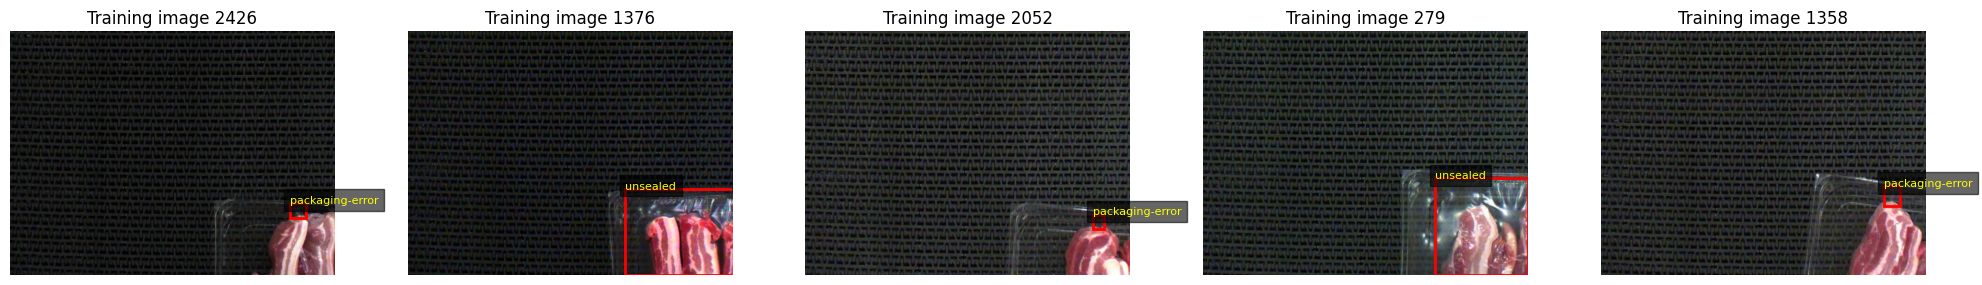

In [4]:

# Display five reproducibly selected images and annotation boxes.

rng = np.random.default_rng(SEED)

sample_indices = rng.choice(
    len(train_dataset),
    size=5,
    replace=False,
)

fig, axes = plt.subplots(
    1,
    len(sample_indices),
    figsize=(20, 5),
)

for ax, index in zip(axes, sample_indices):
    image, target = train_dataset[int(index)]

    ax.imshow(image.permute(1, 2, 0).numpy())

    for box, label in zip(
        target["boxes"],
        target["labels"],
    ):
        x1, y1, x2, y2 = box.tolist()
        class_name = CLASS_NAMES[int(label) - 1]

        rectangle = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )

        ax.add_patch(rectangle)

        ax.text(
            x1,
            y1,
            class_name,
            fontsize=8,
            color="yellow",
            bbox={
                "facecolor": "black",
                "alpha": 0.6,
            },
        )

    ax.set_title(f"Training image {int(index)}")
    ax.axis("off")

plt.tight_layout()
plt.show()
plt.close(fig)


## 2. Saved Faster R-CNN Checkpoint

The original Faster R-CNN ResNet50-FPN V2 model was initialised with COCO-pretrained weights and fine-tuned for 15 epochs.

Its classification and bounding-box prediction head was modified to support four defect categories and one background class.

The best checkpoint was selected using validation mAP@50:95. The shared model-loading module reconstructs the architecture and loads the existing weights with strict parameter verification.

The original 640-pixel preprocessing and inference postprocessing settings are restored before evaluation.

## 3. Training Performance Analysis

The saved `training_history.csv` contains training loss, validation mAP and recorded epoch duration for each of the 15 epochs.

These historical records are used to display training curves and identify the best epoch. No optimisation, backpropagation or new training is performed.

In [5]:

# Load the original Faster R-CNN best checkpoint without training.

faster_rcnn = load_experiment_model(
    project_root=project_root,
    run_name="faster_rcnn_4class",
    device=device,
)

# Restore the original input-resizing configuration.
faster_rcnn.transform.min_size = (640,)
faster_rcnn.transform.max_size = 640

# Restore the original detection postprocessing.
faster_rcnn.roi_heads.score_thresh = 0.001
faster_rcnn.roi_heads.nms_thresh = 0.50
faster_rcnn.roi_heads.detections_per_img = 100

faster_rcnn.eval()

# Read historical checkpoint metadata using tensor-only loading.
checkpoint_metadata = torch.load(
    best_model_path,
    map_location="cpu",
    weights_only=True,
)

saved_epoch = int(checkpoint_metadata["epoch"])
saved_map = float(checkpoint_metadata["val_map"])

print("Faster R-CNN checkpoint loaded.")
print("Best epoch:", saved_epoch)
print("Saved validation mAP@50:95:", round(saved_map, 4))

print(
    "Image-size settings:",
    faster_rcnn.transform.min_size,
    faster_rcnn.transform.max_size,
)

print(
    "Internal score threshold:",
    faster_rcnn.roi_heads.score_thresh,
)
print(
    "NMS threshold:",
    faster_rcnn.roi_heads.nms_thresh,
)
print(
    "Maximum detections:",
    faster_rcnn.roi_heads.detections_per_img,
)

assert saved_epoch == 3
assert abs(saved_map - 0.3222) < 0.001

del checkpoint_metadata


Faster R-CNN checkpoint loaded.
Best epoch: 3
Saved validation mAP@50:95: 0.3222
Image-size settings: (640,) 640
Internal score threshold: 0.001
NMS threshold: 0.5
Maximum detections: 100


ORIGINAL TRAINING HISTORY


,Epoch,Train_Loss,Val_mAP50,Val_mAP50_95,Epoch_Seconds
0,1,0.1549,0.3299,0.1883,265.3867
1,2,0.0956,0.4093,0.1983,287.1151
2,3,0.0686,0.5662,0.3222,291.0855
3,4,0.0496,0.4661,0.3036,292.0423
4,5,0.0371,0.5370,0.3130,290.6363
5,6,0.0245,0.5280,0.3149,291.6250
6,7,0.0183,0.5250,0.3095,290.7815
7,8,0.0158,0.5011,0.2810,298.7953
8,9,0.0142,0.5270,0.2788,292.6684
9,10,0.0131,0.5342,0.2913,291.1179


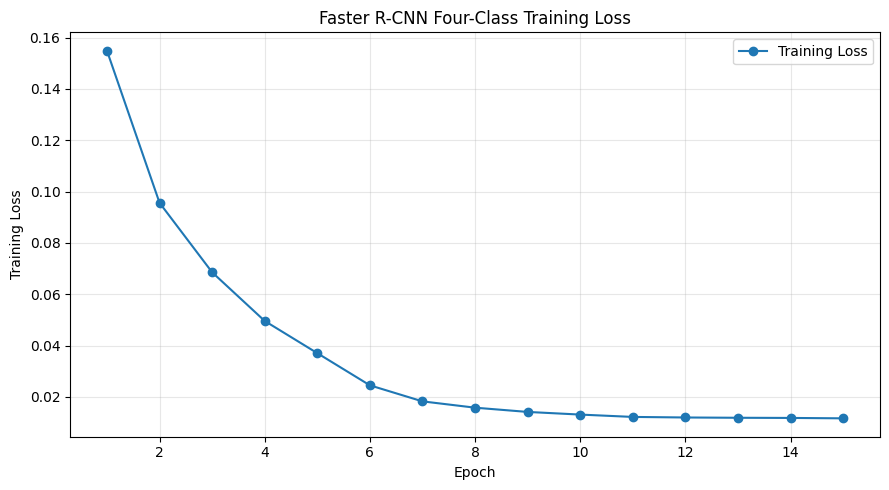

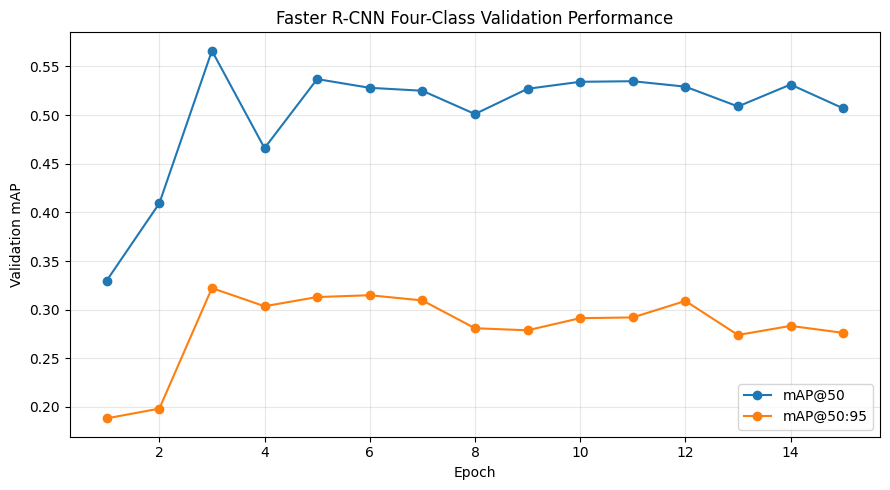

Best epoch: 3
Best historical mAP@50:95: 0.3222
Historical epoch-duration sum: 4361.44 seconds


In [6]:

# Reproduce training-history figures from the original saved CSV.

history_path = run_dir / "training_history.csv"

if not history_path.is_file():
    raise FileNotFoundError(
        f"Original training history missing: {history_path}"
    )

history_df = pd.read_csv(history_path)
history_df.columns = history_df.columns.str.strip()

required_columns = [
    "Epoch",
    "Train_Loss",
    "Val_mAP50",
    "Val_mAP50_95",
    "Epoch_Seconds",
]

assert all(
    column in history_df.columns
    for column in required_columns
)

assert len(history_df) == 15

print("ORIGINAL TRAINING HISTORY")
display(history_df.round(4))

loss_figure = plot_training_history(
    history_df,
    metric_columns={
        "Train_Loss": "Training Loss",
    },
    epoch_column="Epoch",
    title="Faster R-CNN Four-Class Training Loss",
    ylabel="Training Loss",
)

loss_figure.savefig(
    output_dir / "training_loss.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(loss_figure)

map_figure = plot_training_history(
    history_df,
    metric_columns={
        "Val_mAP50": "mAP@50",
        "Val_mAP50_95": "mAP@50:95",
    },
    epoch_column="Epoch",
    title="Faster R-CNN Four-Class Validation Performance",
    ylabel="Validation mAP",
)

map_figure.savefig(
    output_dir / "validation_map.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(map_figure)

best_history_row = history_df.loc[
    history_df["Val_mAP50_95"].idxmax()
]

historical_training_seconds = float(
    history_df["Epoch_Seconds"].sum()
)

print("Best epoch:", int(best_history_row["Epoch"]))
print(
    "Best historical mAP@50:95:",
    round(float(best_history_row["Val_mAP50_95"]), 4),
)
print(
    "Historical epoch-duration sum:",
    round(historical_training_seconds, 2),
    "seconds",
)

assert int(best_history_row["Epoch"]) == saved_epoch


## 4. Overall and Per-Class Validation Performance

The selected best checkpoint is evaluated using the complete four-class validation split.

The COCO-style evaluation includes mAP@50, mAP@50:95, mAP@75 and mAR@100, calculated with TorchMetrics.

Per-class average precision is examined to identify differences in defect detection performance.

The evaluation uses only the saved checkpoint and the original validation images. The held-out test split is not used for threshold selection.

In [7]:

# Generate all validation predictions once and reuse them for evaluation.

@torch.inference_mode()
def collect_predictions(model, data_loader, inference_device):
      """Collect model predictions and targets for object detection evaluation.

    Args:
        model: Trained Torchvision object detection model.
        data_loader: DataLoader providing images and ground-truth targets.
        inference_device: PyTorch device used for model inference.

    Returns:
        Tuple containing lists of prediction dictionaries and
        ground-truth dictionaries. All tensors are stored on the CPU.
    """
    # Collect predictions and targets in a consistent image order.
    model.eval()

    predictions = []
    targets = []

    for images, batch_targets in data_loader:
        images_device = [
            image.to(inference_device)
            for image in images
        ]

        batch_predictions = model(images_device)

        for prediction, target in zip(
            batch_predictions,
            batch_targets,
        ):
            predictions.append({
                "boxes": prediction["boxes"].detach().cpu(),
                "scores": prediction["scores"].detach().cpu(),
                "labels": prediction["labels"].detach().cpu().long(),
            })

            targets.append({
                "boxes": target["boxes"].detach().cpu(),
                "labels": target["labels"].detach().cpu().long(),
            })

    return predictions, targets


predictions_all, targets_all = collect_predictions(
    faster_rcnn,
    valid_loader,
    device,
)

assert len(predictions_all) == len(valid_dataset)
assert len(targets_all) == len(valid_dataset)

print("Prediction images:", len(predictions_all))
print("Ground-truth images:", len(targets_all))

print(
    "Total predictions:",
    sum(len(record["scores"]) for record in predictions_all),
)

print(
    "Internal score threshold:",
    faster_rcnn.roi_heads.score_thresh,
)


Prediction images: 120
Ground-truth images: 120
Total predictions: 1427
Internal score threshold: 0.001


In [8]:

# Calculate overall and per-class COCO metrics using saved predictions.

metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=True,
)

metric.update(predictions_all, targets_all)

validation_results = metric.compute()

overall_ap_df = pd.DataFrame([{
    "mAP@50": float(validation_results["map_50"]),
    "mAP@50:95": float(validation_results["map"]),
    "mAP@75": float(validation_results["map_75"]),
    "mAR@100": float(validation_results["mar_100"]),
}])

class_ap_mapping = {
    int(class_id): float(ap)
    for class_id, ap in zip(
        validation_results["classes"],
        validation_results["map_per_class"],
    )
}

per_class_ap_df = pd.DataFrame([
    {
        "Class": name,
        "mAP@50:95": class_ap_mapping.get(class_id, np.nan),
    }
    for class_id, name in enumerate(CLASS_NAMES, start=1)
])

print("FASTER R-CNN FOUR-CLASS VALIDATION RESULTS")
display(overall_ap_df.round(4))

print("\nPER-CLASS AVERAGE PRECISION")
display(per_class_ap_df.round(4))

print("\nORIGINAL VALIDATION REPRODUCIBILITY")

observed_map50 = float(validation_results["map_50"])
observed_map = float(validation_results["map"])

map50_match = abs(observed_map50 - 0.5662) <= 0.005
map_match = abs(observed_map - 0.3222) <= 0.005

print("mAP@50 matches:", map50_match)
print("mAP@50:95 matches:", map_match)

if not (map50_match and map_match):
    print(
        "WARNING: Validation metrics differ from the original "
        "experiment. Check preprocessing and postprocessing."
    )


FASTER R-CNN FOUR-CLASS VALIDATION RESULTS


,mAP@50,mAP@50:95,mAP@75,mAR@100
0,0.5662,0.3222,0.339,0.4262



PER-CLASS AVERAGE PRECISION


,Class,mAP@50:95
0,loose-meat,0.4663
1,packaging-error,0.0458
2,twisted-meat,0.2020
3,unsealed,0.5748



ORIGINAL VALIDATION REPRODUCIBILITY
mAP@50 matches: True
mAP@50:95 matches: True


## 5. Confidence-Threshold Evaluation

The saved predictions are evaluated at five confidence thresholds: 0.10, 0.25, 0.50, 0.70 and 0.849.

Detection matching uses an IoU threshold of 0.50 and one-to-one matching between predictions and ground-truth boxes.

The confusion matrices represent predicted categories in rows, actual categories in columns and background in the final row and column.

Micro-F1 summarises detection performance across all classes, whereas Macro-F1 assigns equal weight to the four defect categories.

## 6. Confusion Matrix Analysis

Five raw and five column-normalised confusion matrices are displayed. These show correct classifications, incorrect-class matches, false detections and missed objects.

FIVE-THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1
0,0.100,89,82,32,0.5205,0.7355,0.6096,0.4375
1,0.250,84,52,37,0.6176,0.6942,0.6537,0.4931
2,0.500,80,34,41,0.7018,0.6612,0.6809,0.5962
3,0.700,75,22,46,0.7732,0.6198,0.6881,0.3910
4,0.849,72,16,49,0.8182,0.5950,0.6890,0.2531



CORRECT DETECTIONS BY CLASS


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,2,13,1,73
0.250,2,10,1,71
0.500,2,7,1,70
0.700,0,5,1,69
0.849,0,3,0,69



PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,0.6667,0.3824,0.3333,0.9012
0.250,0.6667,0.2941,0.3333,0.8765
0.500,0.6667,0.2059,0.3333,0.8642
0.700,0.0000,0.1471,0.3333,0.8519
0.849,0.0000,0.0882,0.0000,0.8519


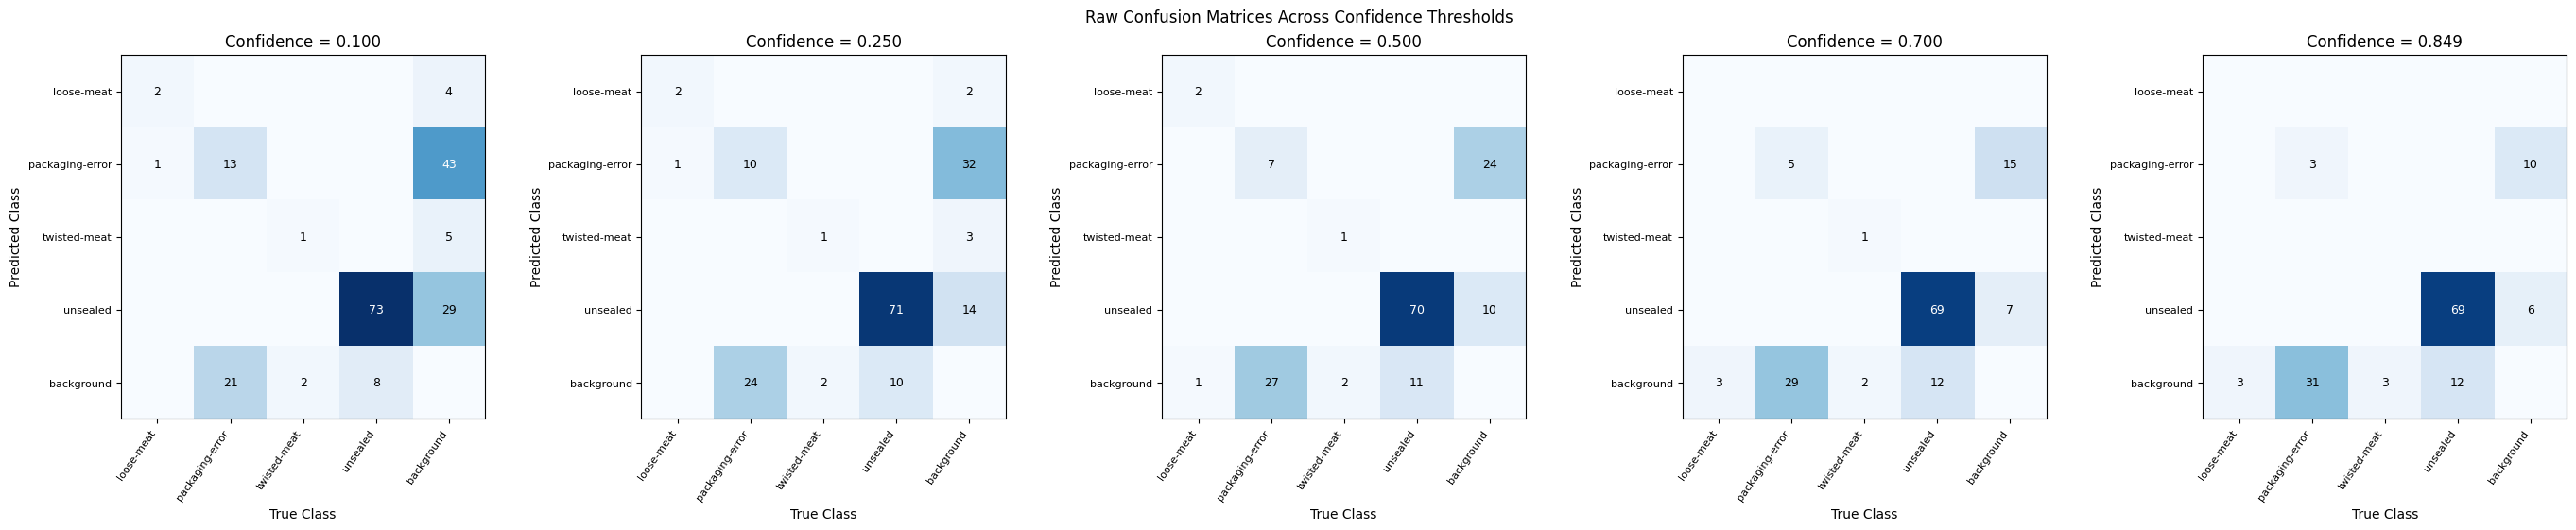

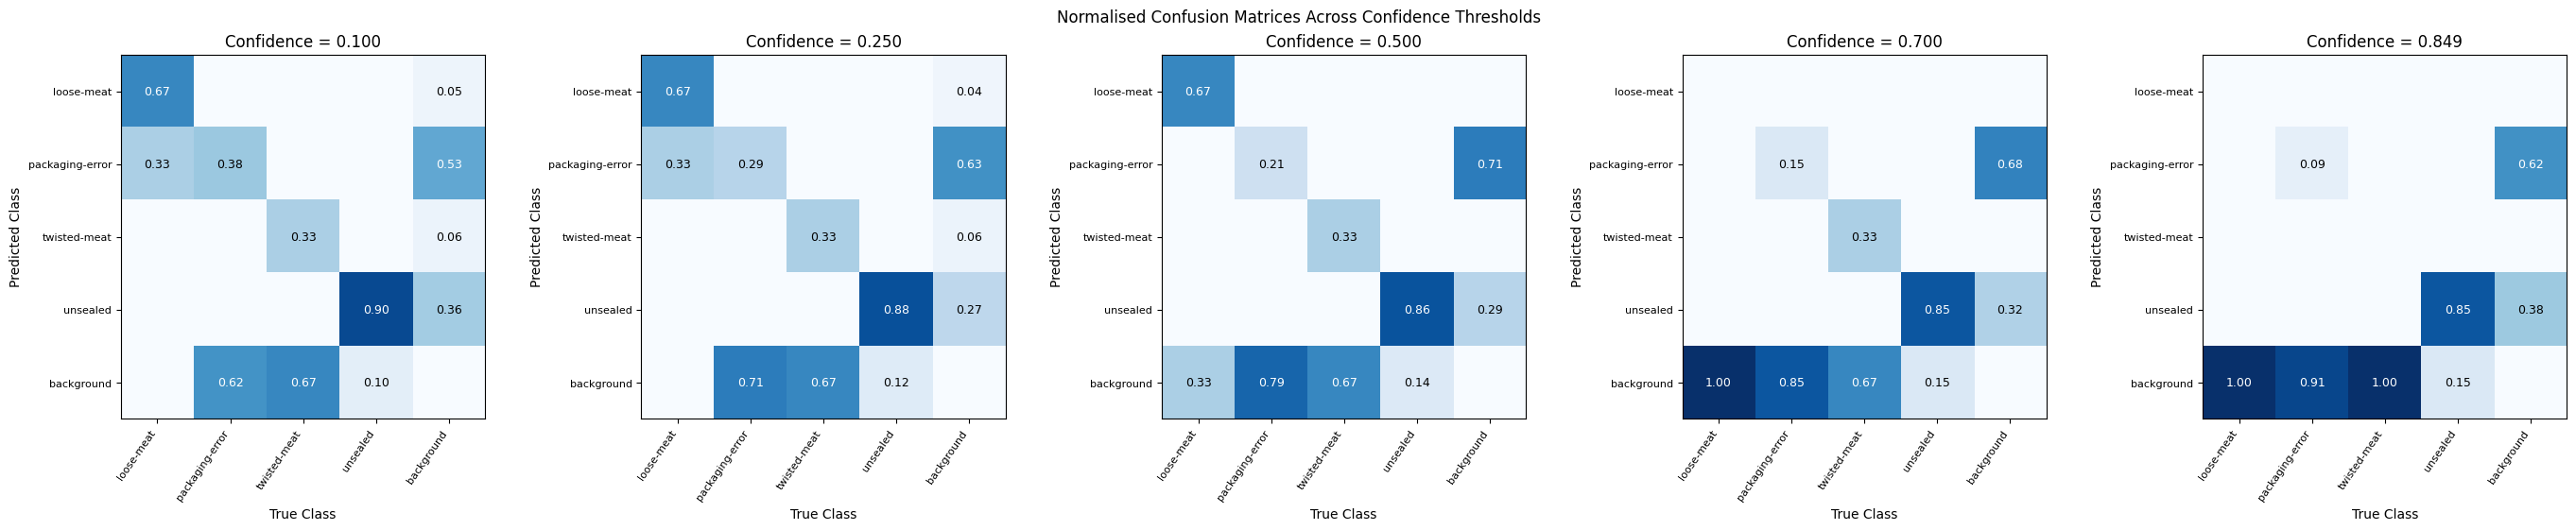

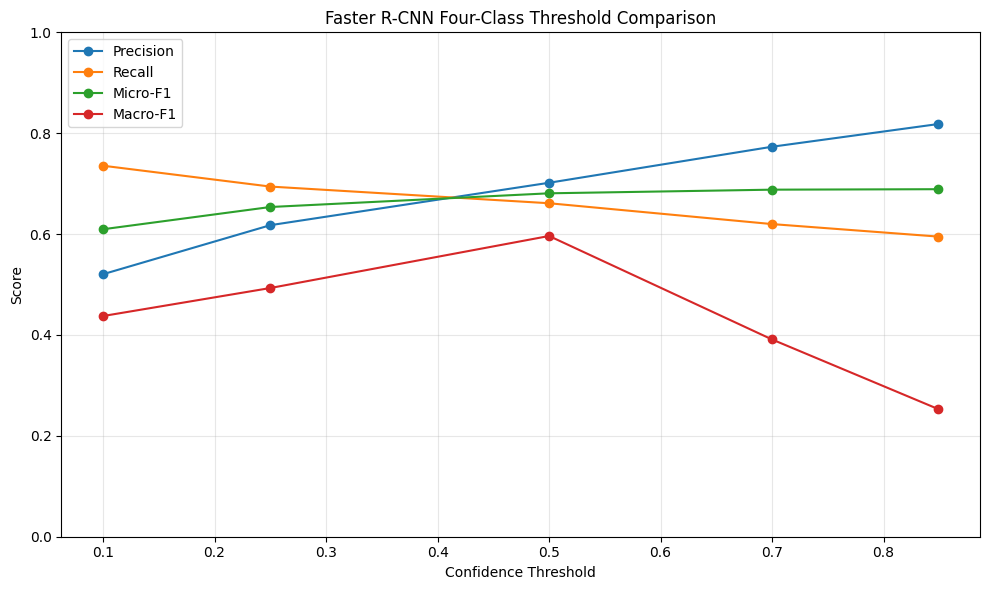


BEST MICRO-F1 AMONG FIVE THRESHOLDS
Threshold: 0.849
Micro-F1: 0.6890


In [9]:

# Evaluate the five original confidence thresholds with shared matching.

THRESHOLDS = [0.10, 0.25, 0.50, 0.70, 0.849]
IOU_THRESHOLD = 0.50

summary_df, class_df, matrices = evaluate_thresholds(
    predictions=predictions_all,
    targets=targets_all,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    iou_threshold=IOU_THRESHOLD,
    label_offset=1,
)

summary_df = summary_df.rename(columns={
    "F1": "Micro-F1",
})

print("FIVE-THRESHOLD COMPARISON")

display(summary_df[
    [
        "Threshold",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ]
].round(4))

print("\nCORRECT DETECTIONS BY CLASS")
display(correct_detections_table(class_df))

print("\nPER-CLASS RECALL")
display(per_class_recall_table(class_df).round(4))

raw_figure = plot_confusion_matrices(
    matrices=matrices,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    normalized=False,
)

raw_figure.savefig(
    output_dir / "confusion_matrices_raw.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(raw_figure)

normalized_figure = plot_confusion_matrices(
    matrices=matrices,
    thresholds=THRESHOLDS,
    class_names=CLASS_NAMES,
    normalized=True,
)

normalized_figure.savefig(
    output_dir / "confusion_matrices_normalized.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(normalized_figure)

# Retain the five-threshold performance graph.
comparison_figure = plot_threshold_metrics(
    summary_df,
    metric_columns=[
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ],
    title="Faster R-CNN Four-Class Threshold Comparison",
)

comparison_figure.savefig(
    output_dir / "threshold_comparison.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(comparison_figure)

best_tested = select_best_threshold(
    summary_df,
    metric="Micro-F1",
)

print("\nBEST MICRO-F1 AMONG FIVE THRESHOLDS")
print(f"Threshold: {best_tested['Threshold']:.3f}")
print(f"Micro-F1: {best_tested['Micro-F1']:.4f}")


## 7. Fine Confidence-Threshold Sensitivity

A finer confidence sweep from 0.10 to 0.50, in increments of 0.025, is conducted using the same saved validation predictions.

Precision, recall, Micro-F1, Macro-F1 and per-class recall are compared across the candidate thresholds.

The best Micro-F1 and Macro-F1 thresholds are selected independently from validation performance. This experiment does not use the held-out test set for operating-point selection.

FINE THRESHOLD COMPARISON


,Threshold,TP,FP,FN,Precision,Recall,Micro-F1,Macro-F1,Macro-Recall
0,0.100,89,82,32,0.5205,0.7355,0.6096,0.4375,0.5709
1,0.125,88,75,33,0.5399,0.7273,0.6197,0.4526,0.5635
2,0.150,88,66,33,0.5714,0.7273,0.6400,0.4625,0.5635
3,0.175,88,64,33,0.5789,0.7273,0.6447,0.4642,0.5635
4,0.200,88,59,33,0.5986,0.7273,0.6567,0.4924,0.5635
5,0.225,86,53,35,0.6187,0.7107,0.6615,0.4914,0.5531
6,0.250,84,52,37,0.6176,0.6942,0.6537,0.4931,0.5427
7,0.275,83,50,38,0.6241,0.6860,0.6535,0.5159,0.5353
8,0.300,83,49,38,0.6288,0.6860,0.6561,0.5172,0.5353
9,0.325,83,46,38,0.6434,0.6860,0.6640,0.5201,0.5353



BEST MICRO-F1 THRESHOLD
Threshold: 0.500
Micro-F1: 0.6809
Precision: 0.7018
Recall: 0.6612

BEST MACRO-F1 THRESHOLD
Threshold: 0.500
Macro-F1: 0.5962


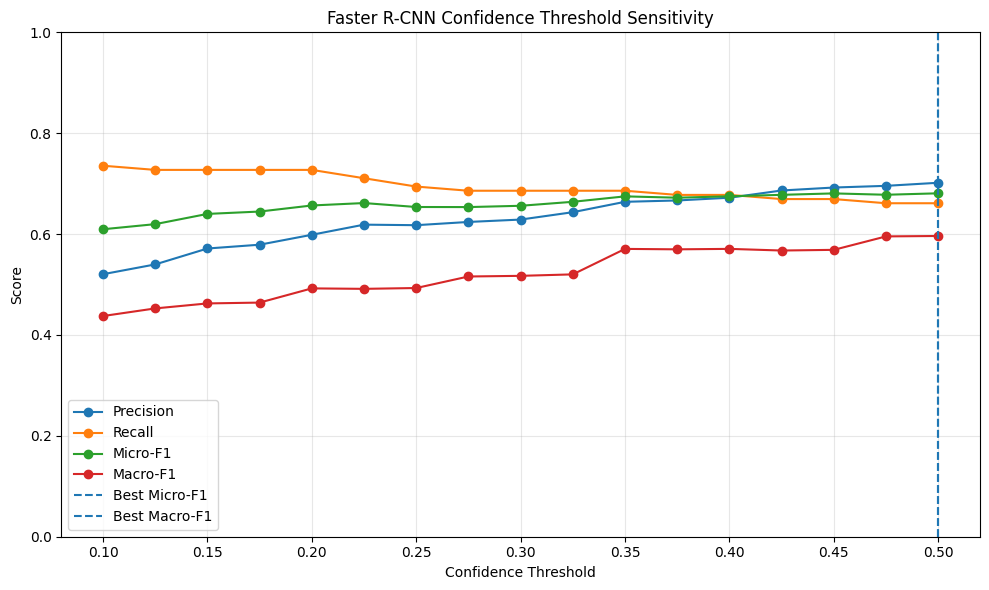

In [10]:

# Compare fine confidence thresholds from 0.10 to 0.50.

FINE_THRESHOLDS = np.round(
    np.arange(0.10, 0.5001, 0.025),
    3,
)

fine_df, fine_class_df, fine_matrices = evaluate_thresholds(
    predictions=predictions_all,
    targets=targets_all,
    thresholds=FINE_THRESHOLDS,
    class_names=CLASS_NAMES,
    iou_threshold=IOU_THRESHOLD,
    label_offset=1,
)

fine_df = fine_df.rename(columns={
    "F1": "Micro-F1",
})

print("FINE THRESHOLD COMPARISON")

display(fine_df[
    [
        "Threshold",
        "TP",
        "FP",
        "FN",
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
        "Macro-Recall",
    ]
].round(4))

best_micro = select_best_threshold(
    fine_df,
    metric="Micro-F1",
)

best_macro = select_best_threshold(
    fine_df,
    metric="Macro-F1",
)

print("\nBEST MICRO-F1 THRESHOLD")
print(f"Threshold: {best_micro['Threshold']:.3f}")
print(f"Micro-F1: {best_micro['Micro-F1']:.4f}")
print(f"Precision: {best_micro['Precision']:.4f}")
print(f"Recall: {best_micro['Recall']:.4f}")

print("\nBEST MACRO-F1 THRESHOLD")
print(f"Threshold: {best_macro['Threshold']:.3f}")
print(f"Macro-F1: {best_macro['Macro-F1']:.4f}")

figure = plot_threshold_metrics(
    fine_df,
    metric_columns=[
        "Precision",
        "Recall",
        "Micro-F1",
        "Macro-F1",
    ],
    title="Faster R-CNN Confidence Threshold Sensitivity",
    selected_thresholds={
        "Best Micro-F1": float(best_micro["Threshold"]),
        "Best Macro-F1": float(best_macro["Threshold"]),
    },
)

figure.savefig(
    output_dir / "fine_threshold_sensitivity.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)


PER-CLASS RECALL


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.100,0.6667,0.3824,0.3333,0.9012
0.125,0.6667,0.3529,0.3333,0.9012
0.150,0.6667,0.3529,0.3333,0.9012
0.175,0.6667,0.3529,0.3333,0.9012
0.200,0.6667,0.3529,0.3333,0.9012
0.225,0.6667,0.3235,0.3333,0.8889
0.250,0.6667,0.2941,0.3333,0.8765
0.275,0.6667,0.2647,0.3333,0.8765
0.300,0.6667,0.2647,0.3333,0.8765


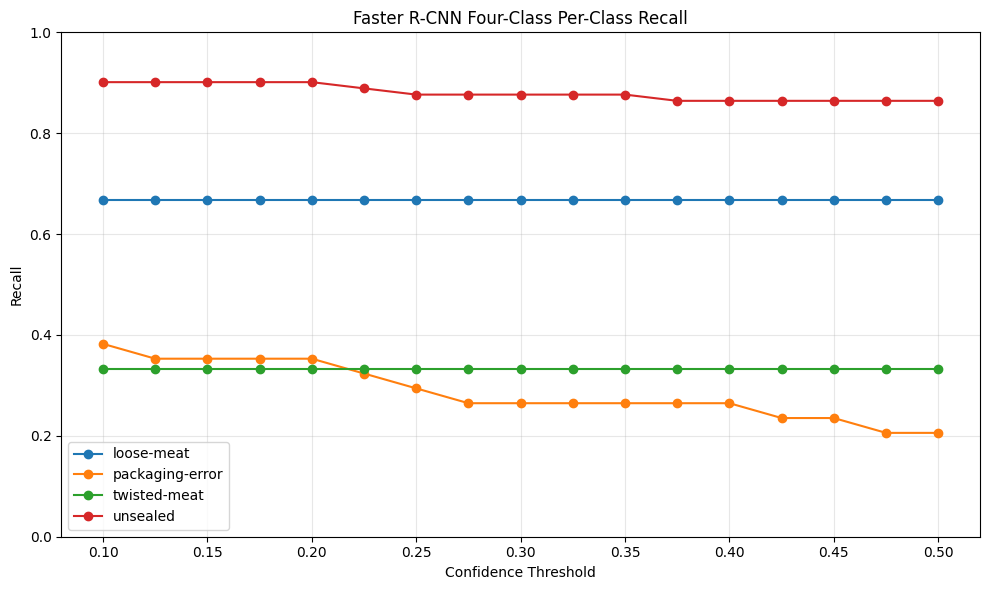


PER-CLASS PERFORMANCE AT SELECTED THRESHOLDS


,Threshold,Class,TP,FP,FN,Precision,Recall,F1
64,0.5,loose-meat,2,0,1,1.0000,0.6667,0.8000
65,0.5,packaging-error,7,24,27,0.2258,0.2059,0.2154
66,0.5,twisted-meat,1,0,2,1.0000,0.3333,0.5000
67,0.5,unsealed,70,10,11,0.8750,0.8642,0.8696



RECALL AT SELECTED THRESHOLDS


Class,loose-meat,packaging-error,twisted-meat,unsealed
Threshold,,,,
0.5,0.6667,0.2059,0.3333,0.8642


In [11]:

# Examine recall sensitivity for each defect category.

recall_table = per_class_recall_table(
    fine_class_df
)

print("PER-CLASS RECALL")
display(recall_table.round(4))

figure = plot_per_class_recall(
    recall_table,
    title="Faster R-CNN Four-Class Per-Class Recall",
)

figure.savefig(
    output_dir / "per_class_recall.png",
    dpi=160,
    bbox_inches="tight",
)

plt.show()
plt.close(figure)

selected_thresholds = sorted({
    float(best_micro["Threshold"]),
    float(best_macro["Threshold"]),
})

selected_mask = np.isclose(
    fine_class_df["Threshold"].to_numpy()[:, None],
    selected_thresholds,
).any(axis=1)

print("\nPER-CLASS PERFORMANCE AT SELECTED THRESHOLDS")
display(
    fine_class_df.loc[selected_mask].round(4)
)

print("\nRECALL AT SELECTED THRESHOLDS")
display(
    recall_table.loc[
        recall_table.index.isin(selected_thresholds)
    ].round(4)
)


## 8. Computational Performance

The saved Faster R-CNN model is evaluated for parameter count, checkpoint storage, inference latency, approximate throughput and peak GPU memory.

The model is warmed up before timing. Fifty single-image inference passes are then measured using the current Colab runtime.

Training duration is recovered from the original saved training-history file. It is a historical measurement and is not recalculated through training.

Runtime performance may vary with GPU hardware, installed packages and background system activity.

## 9. Findings and Limitations

The saved Faster R-CNN model achieved a historical validation mAP@50:95 of approximately 0.3222, with the best checkpoint selected at epoch 3 of 15.

Validation performance varied between epochs despite the continued decline in training loss, highlighting the importance of checkpoint selection using validation metrics.

Per-class results indicate comparatively stronger loose-meat and unsealed detection, whereas packaging-error AP remains low.

The confidence-threshold analysis illustrates the balance between missed defects and false detections. Micro-F1 and Macro-F1 provide complementary perspectives because the validation categories are imbalanced.

### Limitations

- Relatively few loose-meat and twisted-meat annotations are present in validation data.
- The original annotations are treated as reference labels, not independently confirmed ground truth.
- Confidence thresholds are selected using validation data only.
- Computational results depend on the hardware and software environment.
- This notebook evaluates a saved model rather than rerunning training.

The final three-model validation and held-out test comparisons will be performed in Notebook 07.

In [12]:

# Benchmark the saved Faster R-CNN detector without retraining.

parameters = count_parameters(faster_rcnn)

parameter_count = parameters["Total Parameters"]

checkpoint_size_mb = (
    best_model_path.stat().st_size / (1024 ** 2)
)

sample_image, _ = valid_dataset[0]
sample_image = sample_image.to(device)

faster_rcnn.eval()

# Warm up the detector before timing.
with torch.inference_mode():
    for _ in range(10):
        _ = faster_rcnn([sample_image])

if device.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

inference_times = []

with torch.inference_mode():
    for _ in range(50):
        if device.type == "cuda":
            torch.cuda.synchronize()

        start_time = time.perf_counter()

        _ = faster_rcnn([sample_image])

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed_ms = (
            time.perf_counter() - start_time
        ) * 1000

        inference_times.append(elapsed_ms)

median_inference_ms = float(
    np.median(inference_times)
)

fps = (
    1000.0 / median_inference_ms
    if median_inference_ms > 0
    else np.nan
)

if device.type == "cuda":
    peak_gpu_mb = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 2)
    )
else:
    peak_gpu_mb = np.nan

compute_results = pd.DataFrame([{
    "Model": "Faster R-CNN ResNet50-FPN V2",
    "Parameters": parameter_count,
    "Checkpoint_MB": checkpoint_size_mb,
    "Inference_ms": median_inference_ms,
    "FPS": fps,
    "Peak_GPU_MB": peak_gpu_mb,
    "Training_seconds": historical_training_seconds,
}])

print("FASTER R-CNN COMPUTATIONAL PERFORMANCE")
display(compute_results.round(4))

print(
    "\nHistorical training duration:",
    round(historical_training_seconds, 2),
    "seconds",
)
print("Current inference benchmark device:", device)


FASTER R-CNN COMPUTATIONAL PERFORMANCE


,Model,Parameters,Checkpoint_MB,Inference_ms,FPS,Peak_GPU_MB,Training_seconds
0,Faster R-CNN ResNet50-FPN V2,43271528,329.6558,101.3662,9.8652,647.8721,4361.4358



Historical training duration: 4361.44 seconds
Current inference benchmark device: cuda


In [14]:

# Verify that the cleaned notebook reproduces the original results.

reference_validation = {
    "mAP@50": 0.5662,
    "mAP@50:95": 0.3222,
}

reference_threshold_counts = {
    0.100: (89, 82, 32),
    0.250: (84, 52, 37),
    0.500: (80, 34, 41),
    0.700: (75, 22, 46),
    0.849: (72, 16, 49),
}

print("FASTER R-CNN REPRODUCIBILITY CHECKS")

print("\nVALIDATION METRICS")

validation_pass = True

for metric_name, reference in reference_validation.items():
    observed = float(overall_ap_df.iloc[0][metric_name])

    matches = abs(observed - reference) <= 0.005

    validation_pass = validation_pass and matches

    print(
        f"{metric_name}: observed={observed:.4f}, "
        f"reference={reference:.4f}, match={matches}"
    )

print("\nFIVE-THRESHOLD DETECTION COUNTS")

threshold_pass = True

for threshold, reference_counts in reference_threshold_counts.items():
    row = summary_df.loc[
        np.isclose(summary_df["Threshold"], threshold)
    ].iloc[0]

    observed_counts = (
        int(row["TP"]),
        int(row["FP"]),
        int(row["FN"]),
    )

    matches = observed_counts == reference_counts
    threshold_pass = threshold_pass and matches

    print(
        f"Threshold {threshold:.3f}: "
        f"observed={observed_counts}, "
        f"reference={reference_counts}, "
        f"match={matches}"
    )

print("\nFINE-THRESHOLD SELECTION")

micro_threshold_match = np.isclose(
    float(best_micro["Threshold"]),
    0.500,
)

macro_threshold_match = np.isclose(
    float(best_macro["Threshold"]),
    0.500,
)

micro_score_match = abs(
    float(best_micro["Micro-F1"]) - 0.6809
) <= 0.005

macro_score_match = abs(
    float(best_macro["Macro-F1"]) - 0.5962
) <= 0.005

print("Micro-F1 threshold matches:", micro_threshold_match)
print("Micro-F1 score matches:", micro_score_match)
print("Macro-F1 threshold matches:", macro_threshold_match)
print("Macro-F1 score matches:", macro_score_match)

all_checks_pass = all([
    validation_pass,
    threshold_pass,
    micro_threshold_match,
    macro_threshold_match,
    micro_score_match,
    macro_score_match,
])

print("\nFINAL STATUS")

if all_checks_pass:
    print("PASS")
else:
    print(
        "REVIEW REQUIRED"
    )

print("\nNo model training was performed.")
print("No dataset generation was performed.")
print("The original checkpoint was not modified.")
print("New figures are stored in:", output_dir)


FASTER R-CNN REPRODUCIBILITY CHECKS

VALIDATION METRICS
mAP@50: observed=0.5662, reference=0.5662, match=True
mAP@50:95: observed=0.3222, reference=0.3222, match=True

FIVE-THRESHOLD DETECTION COUNTS
Threshold 0.100: observed=(89, 82, 32), reference=(89, 82, 32), match=True
Threshold 0.250: observed=(84, 52, 37), reference=(84, 52, 37), match=True
Threshold 0.500: observed=(80, 34, 41), reference=(80, 34, 41), match=True
Threshold 0.700: observed=(75, 22, 46), reference=(75, 22, 46), match=True
Threshold 0.849: observed=(72, 16, 49), reference=(72, 16, 49), match=True

FINE-THRESHOLD SELECTION
Micro-F1 threshold matches: True
Micro-F1 score matches: True
Macro-F1 threshold matches: True
Macro-F1 score matches: True

FINAL STATUS
PASS

No model training was performed.
No dataset generation was performed.
The original checkpoint was not modified.
New figures are stored in: /content/notebook06_outputs
